<a href="https://colab.research.google.com/github/Marcoyt184/AI-lab/blob/main/MNIST_Digit_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST Handwritten Digit Classification using TensorFlow/Keras

**Objective:** Build a neural network that classifies grayscale handwritten digit images (0–9).

This notebook:
1. Loads and explores MNIST.
2. Displays sample images.
3. Builds, compiles, and trains a baseline neural network.
4. Evaluates test accuracy and plots accuracy/loss.
5. Predicts five test images and compares actual and predicted labels.
6. Runs an experiment by changing the hidden-layer neuron count.

**Requirements:** Python 3, TensorFlow, NumPy, Matplotlib, Jupyter Notebook.

Install if needed: `pip install tensorflow matplotlib numpy jupyter`

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
np.random.seed(42)
tf.random.set_seed(42)

TensorFlow version: 2.21.0


## 1. Load and explore the MNIST dataset

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)
print("Pixel range before normalization:", x_train.min(), "to", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Pixel range before normalization: 0 to 255


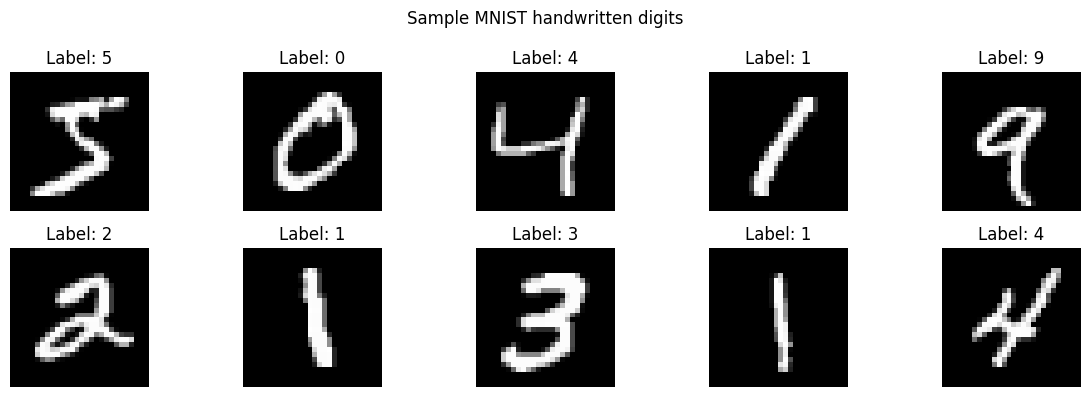

In [3]:
# Display 10 sample training images
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST handwritten digits")
plt.tight_layout()
plt.show()

## 2. Preprocess the data
Each image is 28 × 28 pixels. Pixel values are scaled from 0–255 to 0–1, and images are flattened into 784 input features for a dense neural network.

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train_flat = x_train.reshape(-1, 28 * 28)
x_test_flat = x_test.reshape(-1, 28 * 28)

print("Flattened training shape:", x_train_flat.shape)
print("Flattened testing shape:", x_test_flat.shape)

Flattened training shape: (60000, 784)
Flattened testing shape: (10000, 784)


## 3. Build, compile, and train the baseline model
The baseline network has 128 neurons in one hidden layer with ReLU activation. The output layer has 10 neurons and softmax activation, one for each digit class.

In [5]:
baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
history = baseline_model.fit(
    x_train_flat, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9212 - loss: 0.2741 - val_accuracy: 0.9615 - val_loss: 0.1250
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9634 - loss: 0.1243 - val_accuracy: 0.9703 - val_loss: 0.0993
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9750 - loss: 0.0843 - val_accuracy: 0.9737 - val_loss: 0.0884
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9825 - loss: 0.0617 - val_accuracy: 0.9748 - val_loss: 0.0865
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9873 - loss: 0.0458 - val_accuracy: 0.9758 - val_loss: 0.0869


## 4. Evaluate the model on test data

In [7]:
test_loss, test_accuracy = baseline_model.evaluate(x_test_flat, y_test, verbose=0)
print(f"Baseline test loss: {test_loss:.4f}")
print(f"Baseline test accuracy: {test_accuracy * 100:.2f}%")

Baseline test loss: 0.0865
Baseline test accuracy: 97.37%


## 5. Visualize training and validation accuracy/loss

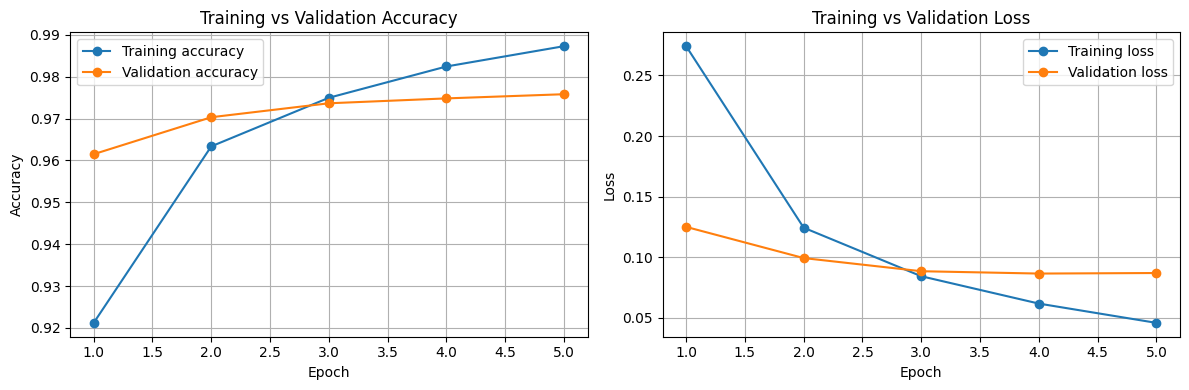

In [8]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs_range, history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 6. Test on five handwritten digit images
These are five images selected from the MNIST test set. The actual labels are supplied by the dataset; the predicted labels come from the trained model.

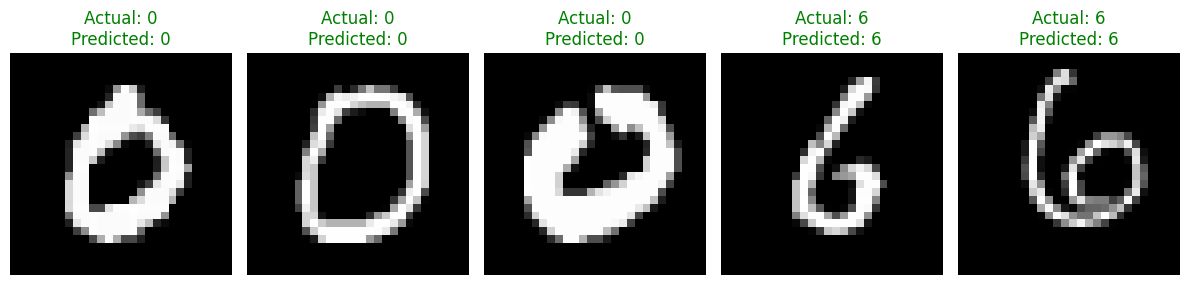

Image 1: Actual=0, Predicted=0 -> Correct
Image 2: Actual=0, Predicted=0 -> Correct
Image 3: Actual=0, Predicted=0 -> Correct
Image 4: Actual=6, Predicted=6 -> Correct
Image 5: Actual=6, Predicted=6 -> Correct


In [9]:
sample_indices = [3, 10, 25, 50, 100]
sample_images = x_test[sample_indices]
sample_inputs = x_test_flat[sample_indices]
actual_labels = y_test[sample_indices]

probabilities = baseline_model.predict(sample_inputs, verbose=0)
predicted_labels = np.argmax(probabilities, axis=1)

plt.figure(figsize=(12, 3))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(sample_images[i], cmap="gray")
    color = "green" if actual_labels[i] == predicted_labels[i] else "red"
    plt.title(f"Actual: {actual_labels[i]}\nPredicted: {predicted_labels[i]}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

for i in range(5):
    result = "Correct" if actual_labels[i] == predicted_labels[i] else "Incorrect"
    print(f"Image {i+1}: Actual={actual_labels[i]}, Predicted={predicted_labels[i]} -> {result}")

## 7. Experiment: increase hidden-layer neurons from 128 to 256
Only the number of neurons is changed. The dataset split, optimizer, loss function, batch size, and epoch count remain the same so that the comparison is meaningful.

In [10]:
experiment_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

experiment_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

experiment_history = experiment_model.fit(
    x_train_flat, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

experiment_loss, experiment_accuracy = experiment_model.evaluate(
    x_test_flat, y_test, verbose=0
)

print(f"Experiment test loss: {experiment_loss:.4f}")
print(f"Experiment test accuracy: {experiment_accuracy * 100:.2f}%")

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9308 - loss: 0.2373 - val_accuracy: 0.9683 - val_loss: 0.1112
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9706 - loss: 0.0977 - val_accuracy: 0.9728 - val_loss: 0.0908
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9818 - loss: 0.0627 - val_accuracy: 0.9742 - val_loss: 0.0857
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9879 - loss: 0.0430 - val_accuracy: 0.9767 - val_loss: 0.0853
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9914 - loss: 0.0298 - val_accuracy: 0.9773 - val_loss: 0.0871
Experiment test loss: 0.0848
Experiment test accuracy: 97.46%


In [11]:
print("MODEL COMPARISON")
print("-" * 45)
print(f"Baseline (128 neurons):   {test_accuracy * 100:.2f}% test accuracy")
print(f"Experiment (256 neurons): {experiment_accuracy * 100:.2f}% test accuracy")
difference = (experiment_accuracy - test_accuracy) * 100
print(f"Difference: {difference:+.2f} percentage points")

if difference > 0:
    print("The 256-neuron model performed better in this run.")
elif difference < 0:
    print("The 128-neuron model performed better in this run.")
else:
    print("Both models achieved the same test accuracy in this run.")

MODEL COMPARISON
---------------------------------------------
Baseline (128 neurons):   97.37% test accuracy
Experiment (256 neurons): 97.46% test accuracy
Difference: +0.09 percentage points
The 256-neuron model performed better in this run.


## 8. Conclusion
The notebook trains a dense neural network to classify MNIST handwritten digits. Record the actual test accuracy values printed above in the report. The experiment compares 128 and 256 hidden-layer neurons. Results can vary slightly depending on the environment and training run.